<a href="https://colab.research.google.com/github/cdube89128/DATA_620/blob/main/Project3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 9 - Project 3 - Name Gender Classifier
### DATA 620
### Catherine Dube

**HW Prompt**

This project assignment is to:

* Using any of the three classifiers described in chapter 6 of Natural Language Processing with Python, and any features you can think of, build the best name gender classifier you can.
* Begin by splitting the Names Corpus into three subsets: 500 words for the test set, 500 words for the dev-test set, and the remaining 6900 words for the training set.
* Then, starting with the example name gender classifier, make incremental improvements. Use the dev-test set to check your progress.
* Once you are satisfied with your classifier, check its final performance on the test set.
* How does the performance on the test set compare to the performance on the dev-test set? Is this what you'd expect?

**My HW Recap**

* I'm using NLTK's Names Corpus, which has ~7.9K first names labeled male or female.
* I started with the book's example classifier, which only looks at the last letter of a name. Then I looked at the names it gets wrong, added features one step at a time, and checked each change on the dev-test set.
* We're allowed to use scikit-learn and to try feature combinations, so here I tried every combination of my feature groups, and I compared the book's three classifiers (naive Bayes, decision tree and maximum entropy) with two from scikit-learn.
* I left the test set alone until the very end, so the final score shows how the classifier does on the names it had never seen.
* What I expect going in: the test score will come in a little lower than the dev-test score, because I'll be picking every feature and the classifier based on how they do on the dev-test set.
* My answers to the prompt's two questions are at the very bottom.

In [ ]:
import random
import textwrap
from collections import Counter
from itertools import combinations

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.classify import SklearnClassifier
from nltk.corpus import names
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

nltk.download("names", quiet=True)

True

## Loading and Splitting the Names Corpus

I'm labeling every name with its gender, shuffling them, and splitting them into the three sets from the prompt.

In [ ]:
# Load and Label the Names
labeled_names = (
    [(name, "male") for name in names.words("male.txt")]
    + [(name, "female") for name in names.words("female.txt")]
)

# Shuffle with a fixed seed so the splits come out the same every run
random.seed(620)
random.shuffle(labeled_names)

# Split: 500 test, 500 dev-test, the rest for training
test_names = labeled_names[:500]
devtest_names = labeled_names[500:1000]
train_names = labeled_names[1000:]

print(f"Total names: {len(labeled_names):,}")
print(f"Training: {len(train_names):,} | Dev-test: {len(devtest_names)} | Test: {len(test_names)}")

Total names: 7,944
Training: 6,944 | Dev-test: 500 | Test: 500


In [ ]:
# A Quick Look at the Data
# Gender balance, names listed as both male and female, and the female share in each set
gender_counts = Counter(g for _, g in labeled_names)
print(f"Male: {gender_counts['male']:,} | Female: {gender_counts['female']:,}")
print(f"Female share: {gender_counts['female'] / len(labeled_names):.1%}")

both_genders = sorted(set(names.words("male.txt")) & set(names.words("female.txt")))
print(f"\n{len(both_genders)} names are listed as both male and female, e.g. {', '.join(both_genders[:12])}")

# A classifier can only guess one gender per name. Checking names that are both male and female.
max_accuracy = 1 - len(both_genders) / len(labeled_names)
print(f"Best possible accuracy with one guess per name: {max_accuracy:.1%}\n")

for label, subset in [("Training", train_names), ("Dev-test", devtest_names), ("Test", test_names)]:
  share = sum(g == "female" for _, g in subset) / len(subset)
  print(f"{label}: {share:.1%} female")

Male: 2,943 | Female: 5,001
Female share: 63.0%

365 names are listed as both male and female, e.g. Abbey, Abbie, Abby, Addie, Adrian, Adrien, Ajay, Alex, Alexis, Alfie, Ali, Alix
Best possible accuracy with one guess per name: 95.4%

Training: 62.7% female
Dev-test: 66.2% female
Test: 63.2% female


In [ ]:
# Baseline: Always Guess the Most Common Gender
# Any real classifier has to at least be better than this
majority_gender = Counter(g for _, g in train_names).most_common(1)[0][0]
baseline_accuracy = sum(g == majority_gender for _, g in devtest_names) / len(devtest_names)
print(f"Always guessing '{majority_gender}' gets {baseline_accuracy:.1%} of the dev-test set right.")

Always guessing 'female' gets 66.2% of the dev-test set right.


**Data Summary**

* The Names Corpus has ~7.9K names, and about 63% of them are female
  * That's ~2.9K male names and ~5K female names. After the split, ~6.9K go to training and 500 each to the dev-test and test sets, and all three sets have about the same share of female names (63–66%).
* Some names are listed as both male and female, which puts a ceiling or a limit on how well any classifier can do
  * 365 names, like Alex, Alexis, Adrian and Ali, are on both lists. A classifier can only guess one gender for a name, so it's guaranteed to get one of the two copies wrong. That alone caps accuracy at about 95%, which is the best possible score printed above.
* If I just guess "female" every time, I get 66% of the dev-test set right, so a classifier only helps if it does better than that.

## Making Incremental Improvements

For each step, I'm changing one thing about the features, training the book's naive Bayes classifier on the training set, and checking how it does on the dev-test set. I'm saving every result so I can compare all the steps at the end.

In [ ]:
# Step 1: Last Letter (like the textbook)
# I adpated this from the book's name gender example: build the feature sets, train naive Bayes, check the accuracy
def features_1(name):
  return {"last_letter": name[-1].lower()}


train_set = [(features_1(n), g) for (n, g) in train_names]
devtest_set = [(features_1(n), g) for (n, g) in devtest_names]
classifier_1 = nltk.NaiveBayesClassifier.train(train_set)
accuracy_1 = nltk.classify.accuracy(classifier_1, devtest_set)

results = [{"step": "1. Last letter", "classifier": "Naive Bayes", "dev_test_accuracy": accuracy_1}]
print(f"1. Last letter: {accuracy_1:.1%} on the dev-test set")
classifier_1.show_most_informative_features(10)

1. Last letter: 76.0% on the dev-test set
Most Informative Features
             last_letter = 'a'            female : male   =     34.6 : 1.0
             last_letter = 'f'              male : female =     28.5 : 1.0
             last_letter = 'k'              male : female =     28.0 : 1.0
             last_letter = 'v'              male : female =     16.2 : 1.0
             last_letter = 'p'              male : female =     15.1 : 1.0
             last_letter = 'd'              male : female =      9.4 : 1.0
             last_letter = 'o'              male : female =      8.8 : 1.0
             last_letter = 'm'              male : female =      8.4 : 1.0
             last_letter = 'r'              male : female =      6.8 : 1.0
             last_letter = 'w'              male : female =      5.3 : 1.0


In [ ]:
# Error Analysis on Step 1
# Adapted from the book's error analysis: list the dev-test names the classifier gets wrong
def show_errors(classifier, feature_fn, n=30):
  errors = []
  for name, gender in devtest_names:
    guess = classifier.classify(feature_fn(name))
    if guess != gender:
      errors.append((gender, guess, name))

  # Count each kind of mistake separately. A single sorted list would always show
  # the female names first, so it couldn't tell me which kind of mistake is more common
  female_as_male = sorted(e for e in errors if e[0] == "female")
  male_as_female = sorted(e for e in errors if e[0] == "male")
  print(f"{len(errors)} errors on the dev-test set:")
  print(f"  Female names guessed as male: {len(female_as_male)}")
  print(f"  Male names guessed as female: {len(male_as_female)}")

  # Names on both the male and female lists: no feature can get both copies right
  both_set = set(both_genders)
  on_both_lists = sorted({name for _, _, name in errors if name in both_set})
  num_on_both = sum(name in both_set for _, _, name in errors)
  print(f"  Mistakes on names that are on both the male and female lists: {num_on_both}")
  print(textwrap.fill("    " + ", ".join(on_both_lists), width=110, subsequent_indent="    ") if on_both_lists else "    none")

  # A sample of each kind
  for label, group in [("Female names guessed as male", female_as_male), ("Male names guessed as female", male_as_female)]:
    print(f"\n{label} (first {min(n, len(group))}):")
    for gender, guess, name in group[:n]:
      print(f"  correct={gender:<7} guess={guess:<7} name={name}")


show_errors(classifier_1, features_1)

120 errors on the dev-test set:
  Female names guessed as male: 69
  Male names guessed as female: 51
  Mistakes on names that are on both the male and female lists: 30
    Abbie, Austin, Caryl, Chrissy, Devon, Dorian, Franky, Gabriel, Gabriell, George, Georgia, Gretchen,
    Haleigh, Haley, Jamie, Jean, Jodie, Lauren, Lindsay, Lorrie, Marlo, Micky, Noel, Sal, Sayre, Shell,
    Tammie, Terri, Theo, Willy

Female names guessed as male (first 30):
  correct=female  guess=male    name=Abigael
  correct=female  guess=male    name=Ardelis
  correct=female  guess=male    name=Arlyn
  correct=female  guess=male    name=Austin
  correct=female  guess=male    name=Bird
  correct=female  guess=male    name=Birgit
  correct=female  guess=male    name=Cameo
  correct=female  guess=male    name=Carin
  correct=female  guess=male    name=Carleen
  correct=female  guess=male    name=Carlyn
  correct=female  guess=male    name=Caron
  correct=female  guess=male    name=Caryl
  correct=female  guess=ma

**Step 1 Error Analysis**

* The book's method of a last-letter classifier gets 76% right
  * Ending in "a" is the strongest sign of a female name, and endings like "f," "k," "v" and "p" point strongly to male. But plenty of female names end in a consonant, so it misses 120 of the 500 dev-test names.
  * The mistakes go both ways: 69 are female names guessed as male, and 51 are male names guessed as female. Since about two-thirds of the dev-test names are female, male names are actually missed at a higher rate (~30% of the male names vs ~21% of the female names).
* Male names that end in a vowel sound are being labeled female
  * Names like Abbie, Archy, Chrissy, Dewey, Jamie, Jodie and Micky end in "-y," "-ie" or "-e," which the classifier links to female names. Others, like Andre, Blaine, George and Keefe, end in an "-e" that's silent or part of a longer ending the last letter can't see.
* A lot of the mistakes share longer endings that one letter can't see
  * Names ending in "-lyn" (Arlyn, Carlyn, Emlyn), "-een" (Carleen, Cathleen, Colleen) and "-is" (Ardelis, Cloris, Corliss) are female, even though their last letter usually means male. The book ran into the same thing with "-yn" names, so next I'm adding the last two and three letters.
* Some mistakes are names that can really go either way
  * Austin, Devon, Dorian and Gabriel are labeled female here, but they're on the male list too, so no ending is going to fix those. Honestly, I'd have guessed male for most of them too.
  * The check above backs this up: 30 of the 120 mistakes (a quarter) are names that show up on both the male and female lists, including all four of those. No feature can get both copies of those names right.

In [ ]:
# Helper for the Rest of the Steps
# try_features does the same thing as step 1
# (build the feature sets, train, check the accuracy on the dev-test set) and saves the result, so I don't have to repeat those lines for every step
def make_sets(feature_fn, train=train_names, devtest=devtest_names):
  train_set = [(feature_fn(n), g) for (n, g) in train]
  devtest_set = [(feature_fn(n), g) for (n, g) in devtest]
  return train_set, devtest_set


def try_features(step, feature_fn, trainer=nltk.NaiveBayesClassifier.train, classifier_name="Naive Bayes", label=None):
  train_set, devtest_set = make_sets(feature_fn)
  classifier = trainer(train_set)
  accuracy = nltk.classify.accuracy(classifier, devtest_set)
  results.append({"step": step, "classifier": classifier_name, "dev_test_accuracy": accuracy})
  # label lets step 8 print just the classifier name under one "Step 8" heading
  print(f"{label or step}: {accuracy:.1%} on the dev-test set")
  return classifier

In [ ]:
# Step 2: Add the Last Two Letters
# Adapted from the book's next step after its error analysis
def features_2(name):
  name = name.lower()
  return {"suffix1": name[-1:], "suffix2": name[-2:]}


classifier_2 = try_features("2. + Last two letters", features_2)

2. + Last two letters: 78.2% on the dev-test set


In [ ]:
# Step 3: Add the Last Three Letters
# For endings like "-ine", "-ica" and "-son"
def features_3(name):
  name = name.lower()
  return {"suffix1": name[-1:], "suffix2": name[-2:], "suffix3": name[-3:]}


classifier_3 = try_features("3. + Last three letters", features_3)

3. + Last three letters: 79.2% on the dev-test set


In [ ]:
# Step 4: Add the First One and Two Letters
def features_4(name):
  name = name.lower()
  return {
      "suffix1": name[-1:],
      "suffix2": name[-2:],
      "suffix3": name[-3:],
      "prefix1": name[:1],
      "prefix2": name[:2],
  }


classifier_4 = try_features("4. + First letters", features_4)

4. + First letters: 82.2% on the dev-test set


In [ ]:
# Step 5: Add Length and Vowels
# Length, number of vowels, and whether the name ends in a vowel
def features_5(name):
  name = name.lower()
  return {
      "suffix1": name[-1:],
      "suffix2": name[-2:],
      "suffix3": name[-3:],
      "prefix1": name[:1],
      "prefix2": name[:2],
      "length": len(name),
      "num_vowels": sum(c in "aeiou" for c in name),
      "ends_in_vowel": name[-1] in "aeiou",
  }


classifier_5 = try_features("5. + Length and vowels", features_5)

5. + Length and vowels: 80.4% on the dev-test set


In [ ]:
# Error Analysis on Step 5
show_errors(classifier_5, features_5)

98 errors on the dev-test set:
  Female names guessed as male: 70
  Male names guessed as female: 28
  Mistakes on names that are on both the male and female lists: 34
    Abbie, Austin, Chrissy, Devon, Dorian, Dory, Eddy, Evelyn, Gabriel, Gabriell, Georgia, Glenn, Gretchen,
    Jamie, Jean, Jodie, Lauren, Lorrie, Lynn, Marlo, Marty, Noel, Rory, Sal, Sammy, Sandy, Sayre, Shay, Shell,
    Tabby, Tammie, Terri, Theo, Toby

Female names guessed as male (first 30):
  correct=female  guess=male    name=Abigael
  correct=female  guess=male    name=Ardelis
  correct=female  guess=male    name=Austin
  correct=female  guess=male    name=Barbe
  correct=female  guess=male    name=Barby
  correct=female  guess=male    name=Bird
  correct=female  guess=male    name=Birgit
  correct=female  guess=male    name=Cameo
  correct=female  guess=male    name=Carin
  correct=female  guess=male    name=Caron
  correct=female  guess=male    name=Cherey
  correct=female  guess=male    name=Clemmy
  correct=f

**Step 5 Error Analysis**

* Adding length and vowels made things a little worse
  * Accuracy dropped from 82% (step 4) to 80%. Length and vowel count mostly repeat what the endings already say, and "ends in a vowel" is decided entirely by the last letter, which the endings already include. The book warns that naive Bayes ends up counting repeated information like that twice.
* There are 98 mistakes, fewer than step 1's 120 but more than step 4 (which got 82% right)
  * 70 are female names guessed as male, about the same as step 1's 69. But only 28 are male names guessed as female, down from 51. So the features added since step 1 mostly fixed mistakes on male names, and female names with "male-looking" endings are still the hard part.
  * A new pattern shows up: nicknames ending in "-y" (Barby, Clemmy, Cynthy, Dory, Gilly, Hally). Lots of male names end in "-y" too, so the endings can't tell these apart.
* What's left are hard names that more letter features probably won't fix
  * They're unusual spellings (Abigael, Debor), nicknames, and names that can go either way (Austin, Devon and Dorian on the female side, Evelyn, Lynn and Glenn on the male side). I think I'm close to the limit of what spelling alone can tell me.
  * The check backs this up too: 34 of the 98 mistakes (about a third) are names on both the male and female lists, including all six of those, up from a quarter in step 1. As the features fix the easier names, more and more of what's left is names that no feature can fix.

In [ ]:
# Step 6: The Kitchen Sink
# Tried based on the book's "kitchen sink" example: first and last letter, plus a count and a yes/no for every letter
# The book warns that this many features overfits the small Names Corpus
def features_6(name):
  name = name.lower()
  features = {"first_letter": name[0], "last_letter": name[-1]}
  for letter in "abcdefghijklmnopqrstuvwxyz":
    features[f"count({letter})"] = name.count(letter)
    features[f"has({letter})"] = letter in name
  return features


classifier_6 = try_features("6. Kitchen sink", features_6)

6. Kitchen sink: 78.0% on the dev-test set


### Trying Feature Combinations

Instead of only adding features in one order, I'm also trying every combination of four feature groups (endings, beginnings, shape, and the letter counts from the kitchen sink) and keeping whichever mix does best on the dev-test set.

In [ ]:
# Step 7: Try Every Combination of Feature Groups
def ending_features(name):
  return {"suffix1": name[-1:], "suffix2": name[-2:], "suffix3": name[-3:]}


def beginning_features(name):
  return {"prefix1": name[:1], "prefix2": name[:2]}


def shape_features(name):
  return {
      "length": len(name),
      "num_vowels": sum(c in "aeiou" for c in name),
      "ends_in_vowel": name[-1] in "aeiou",
  }


def letter_count_features(name):
  return {f"count({c})": name.count(c) for c in "abcdefghijklmnopqrstuvwxyz"}


feature_groups = {
    "endings": ending_features,
    "beginnings": beginning_features,
    "shape": shape_features,
    "letter_counts": letter_count_features,
}


# combine just glues the chosen feature groups together into one feature function
def combine(groups):
  """Build one feature extractor out of a combination of feature groups."""
  def features(name):
    name = name.lower()
    combined = {}
    for group in groups:
      combined.update(feature_groups[group](name))
    return combined
  return features


combo_rows = []
for size in range(1, len(feature_groups) + 1):
  for groups in combinations(feature_groups, size):
    feature_fn = combine(groups)
    train_set, devtest_set = make_sets(feature_fn)
    accuracy = nltk.classify.accuracy(nltk.NaiveBayesClassifier.train(train_set), devtest_set)
    combo_rows.append({"feature_groups": " + ".join(groups), "dev_test_accuracy": accuracy, "feature_fn": feature_fn})

combo_df = pd.DataFrame(combo_rows).sort_values("dev_test_accuracy", ascending=False).reset_index(drop=True)
print(combo_df.drop(columns="feature_fn").to_string(index=False, formatters={"dev_test_accuracy": "{:.1%}".format}))

best_combo = combo_df.iloc[0]
best_features = best_combo["feature_fn"]
results.append({
    "step": f"7. Best combination ({best_combo['feature_groups']})",
    "classifier": "Naive Bayes",
    "dev_test_accuracy": best_combo["dev_test_accuracy"],
})
print(f"\nBest combination: {best_combo['feature_groups']} ({best_combo['dev_test_accuracy']:.1%})")

                              feature_groups dev_test_accuracy
                        endings + beginnings             82.2%
        endings + beginnings + letter_counts             81.8%
                     endings + letter_counts             81.0%
                endings + beginnings + shape             80.4%
endings + beginnings + shape + letter_counts             79.8%
             endings + shape + letter_counts             79.4%
                                     endings             79.2%
                             endings + shape             78.6%
          beginnings + shape + letter_counts             75.0%
                          beginnings + shape             73.8%
                       shape + letter_counts             73.6%
                                       shape             72.2%
                  beginnings + letter_counts             72.0%
                               letter_counts             70.6%
                                  beginnings           

**Feature Combinations Summary**

* The best mix is just the endings plus the beginnings
  * That combination gets 82% on the dev-test set, the same as step 4. Every top combination includes the endings, and every combination without them is stuck between 67% and 75%, so the endings are doing most of the work.
* Adding more features on top doesn't help
  * Adding the letter counts or the shape features to the best mix makes it a little worse every time, and the kitchen sink version only gets 78%. That's the overfitting the book warns about: with too many features, the classifier picks up quirks of the training names that don't carry over to new ones.

## Comparing Classifiers

Now that I have the best features, I'm training all three of the book's classifiers on them, plus logistic regression and a linear support vector machine (SVM) from scikit-learn.

In [ ]:
# Compare Classifiers on the Best Features
trainers = {
    "Naive Bayes": nltk.NaiveBayesClassifier.train,
    "Decision Tree": nltk.DecisionTreeClassifier.train,
    "Maximum Entropy": lambda ts: nltk.MaxentClassifier.train(ts, max_iter=25, trace=0),
    "Logistic Regression (sklearn)": lambda ts: SklearnClassifier(LogisticRegression(max_iter=1000)).train(ts),
    "Linear SVM (sklearn)": lambda ts: SklearnClassifier(LinearSVC(), sparse=False).train(ts),
}

print("--- Step 8: Comparing Classifiers on the Best Features ---")
classifier_scores = {}
for classifier_name, trainer in trainers.items():
  try_features("8. Compare classifiers", best_features, trainer=trainer, classifier_name=classifier_name, label=f"  {classifier_name}")
  classifier_scores[classifier_name] = results[-1]["dev_test_accuracy"]

best_classifier_name = max(classifier_scores, key=classifier_scores.get)
best_trainer = trainers[best_classifier_name]
print(f"\nBest classifier on the dev-test set: {best_classifier_name}, at {classifier_scores[best_classifier_name]:.1%}")

--- Step 8: Comparing Classifiers on the Best Features ---
  Naive Bayes: 82.2% on the dev-test set
  Decision Tree: 72.4% on the dev-test set
  Maximum Entropy: 83.0% on the dev-test set
  Logistic Regression (sklearn): 84.0% on the dev-test set
  Linear SVM (sklearn): 82.6% on the dev-test set

Best classifier on the dev-test set: Logistic Regression (sklearn), at 84.0%


--- Steps 1-7: Feature Changes (Naive Bayes) ---
                                      step dev_test_accuracy
                            1. Last letter             76.0%
                     2. + Last two letters             78.2%
                   3. + Last three letters             79.2%
                        4. + First letters             82.2%
                    5. + Length and vowels             80.4%
                           6. Kitchen sink             78.0%
7. Best combination (endings + beginnings)             82.2%

--- Step 8: Classifiers on the Best Features ---
                   classifier dev_test_accuracy
                  Naive Bayes             82.2%
                Decision Tree             72.4%
              Maximum Entropy             83.0%
Logistic Regression (sklearn)             84.0%
         Linear SVM (sklearn)             82.6%


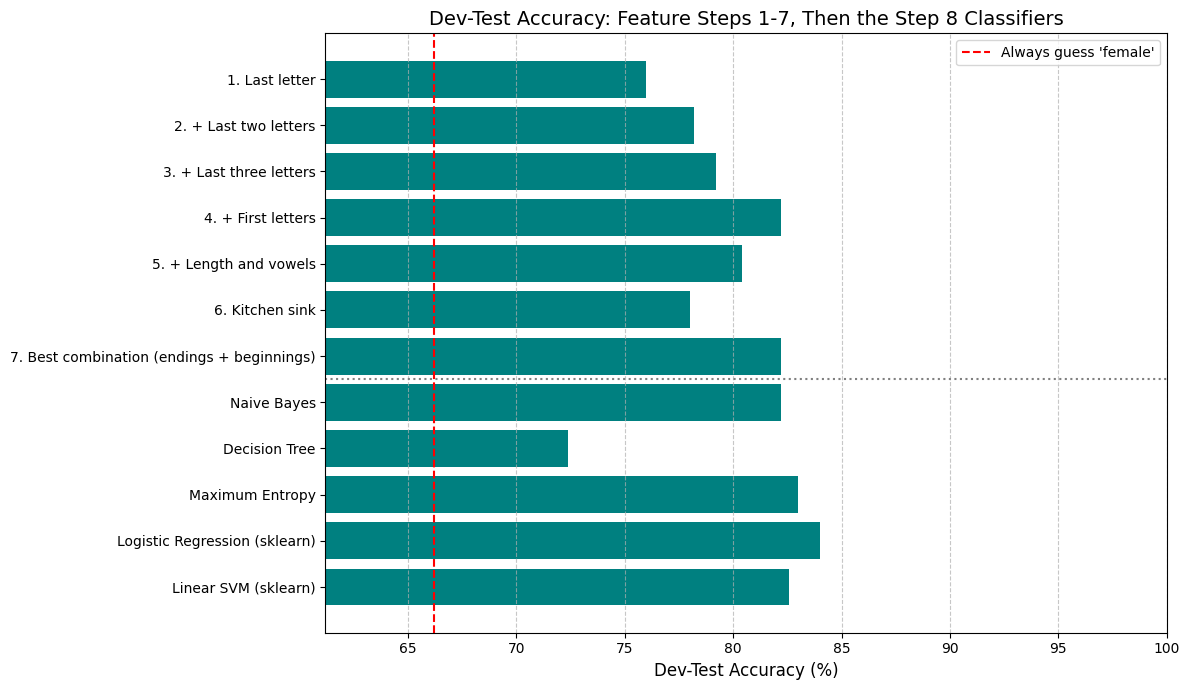

In [ ]:
# All Steps and Classifiers
results_df = pd.DataFrame(results)
is_step_8 = results_df["step"].str.startswith("8.")
accuracy_format = {"dev_test_accuracy": "{:.1%}".format}

print("--- Steps 1-7: Feature Changes (Naive Bayes) ---")
print(results_df.loc[~is_step_8, ["step", "dev_test_accuracy"]].to_string(index=False, formatters=accuracy_format))
print("\n--- Step 8: Classifiers on the Best Features ---")
print(results_df.loc[is_step_8, ["classifier", "dev_test_accuracy"]].to_string(index=False, formatters=accuracy_format))

# Bar labels: steps 1-7 use their step name, and the step 8 bars just use the classifier name
results_df["label"] = results_df["step"].where(~is_step_8, results_df["classifier"])

plt.figure(figsize=(12, 7))
plt.barh(results_df["label"], results_df["dev_test_accuracy"] * 100, color="teal")
# Dotted line between the feature steps (above) and the step 8 classifiers (below)
plt.axhline(is_step_8.idxmax() - 0.5, color="gray", linestyle=":")
plt.axvline(baseline_accuracy * 100, color="red", linestyle="--", label=f"Always guess '{majority_gender}'")
plt.gca().invert_yaxis()
plt.xlim(baseline_accuracy * 100 - 5, 100)
plt.title("Dev-Test Accuracy: Feature Steps 1-7, Then the Step 8 Classifiers", fontsize=14)
plt.xlabel("Dev-Test Accuracy (%)", fontsize=12)
plt.legend()
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

**Classifier Comparison Summary**

* Each feature step from 1 to 4 moved the dev-test score up, from 76% to 82%
  * The biggest jump came from adding the first letters (+3 points).  
* Logistic regression from scikit-learn did best, at 84%
  * Almost all the other models still performed well though/ Maximum entropy (83%), the linear SVM (83%) and naive Bayes (82%) were very close though. SO I wouldn't call this definitevely the best since things might change simply given a different or larger at aset.
* The decision tree was clearly the worst at 72%
  * It didn't surpirse me that a decision tree was not as effective for this classifier. But it did surprise me that it was even worse than the book's one-letter classifier

## Checking the Score With Cross-Validation

I used the same dev-test set for every step, and the book says that after enough rounds of tuning, a classifier can start fitting that particular dev-test set (it suggests switching to a different dev-test split each round). Cross-validation is a way to check for that: I'm splitting the non-test names into 5 folds, letting each fold take a turn as the held-out set, and seeing how much the scores move around. I'm doing this for my best model and for the book's starting classifier.

In [ ]:
# Cross-Validation With 5 Folds
# Each fold takes a turn as the held-out set while the other four are used for training
non_test_names = train_names + devtest_names
num_folds = 5
fold_size = len(non_test_names) // num_folds
cv_rows = []

for fold in range(num_folds):
  held_out = non_test_names[fold * fold_size:(fold + 1) * fold_size]
  training = non_test_names[:fold * fold_size] + non_test_names[(fold + 1) * fold_size:]

  for label, feature_fn, trainer in [
      ("Book's starting classifier", features_1, nltk.NaiveBayesClassifier.train),
      ("My best model", best_features, best_trainer),
  ]:
    train_set, held_out_set = make_sets(feature_fn, training, held_out)
    accuracy = nltk.classify.accuracy(trainer(train_set), held_out_set)
    cv_rows.append({"fold": fold + 1, "model": label, "accuracy": accuracy})

cv_df = pd.DataFrame(cv_rows)
print(f"{num_folds} folds of ~{fold_size:,} names each")
print("Book's starting classifier = last letter, naive Bayes")
print(f"My best model = {best_combo['feature_groups']} features, {best_classifier_name}\n")
print(cv_df.pivot(index="fold", columns="model", values="accuracy").to_string(float_format="{:.1%}".format))
print()
print(cv_df.groupby("model")["accuracy"].agg(["mean", "min", "max"]).to_string(float_format="{:.1%}".format))

5 folds of ~1,488 names each
Book's starting classifier = last letter, naive Bayes
My best model = endings + beginnings features, Logistic Regression (sklearn)

model  Book's starting classifier  My best model
fold                                            
1                           75.5%          81.6%
2                           75.2%          80.7%
3                           78.8%          83.1%
4                           76.7%          82.7%
5                           75.1%          82.7%

                            mean   min   max
model                                       
Book's starting classifier 76.2% 75.1% 78.8%
My best model              82.2% 80.7% 83.1%


**Cross-Validation Summary**

* My best model beats the book's starting classifier on every CV fold
  * Across the 5 folds, logistic regression with endings and beginnings averages 82%, while the last-letter classifier averages 76%.  
* The best model only moves between 81% and 83%, which is a good sign that this score is quite accurate.
* My original dev-test score was 84%, which is still a little higher than what came out of the test sets. But I expected this.

## Final Check on the Test Set

Now that I'm done making changes, I'm training the final classifier on the original training set and checking it on the test set. (The only time I'm testing anything on the true test set.)

In [ ]:
# Final Classifier on the Test Set
# Best features + best classifier, trained on the original training set
final_train_set, final_devtest_set = make_sets(best_features)
final_classifier = best_trainer(final_train_set)
test_set = [(best_features(n), g) for (n, g) in test_names]

devtest_accuracy = nltk.classify.accuracy(final_classifier, final_devtest_set)
test_accuracy = nltk.classify.accuracy(final_classifier, test_set)

print(f"Final model: {best_combo['feature_groups']} features, {best_classifier_name}")
print(f"Dev-test accuracy: {devtest_accuracy:.1%}")
print(f"Test accuracy:     {test_accuracy:.1%}")
print(f"Difference:        {(test_accuracy - devtest_accuracy) * 100:+.1f} percentage points")

Final model: endings + beginnings features, Logistic Regression (sklearn)
Dev-test accuracy: 84.0%
Test accuracy:     79.0%
Difference:        -5.0 percentage points


**Final Test Summary**

* The test score for my final model (logistic regression with endings and beginnings) got 84% on the dev-test set but 79% on the test set.
* A lower test score is what I expected. Of course a model chosen based on its performance on the data prior to now is better and classifying that specific data.
* The test score is a little lower than cross-validation too

## Final Responses

**How does the performance on the test set compare to the performance on the dev-test set?**

* The test score came in lower: 79% on the test set vs 84% on the dev-test set.

**Is this what you'd expect?**

* Yes, that's what I expected going in. I picked every feature and the classifier based on the dev-test set, so its score was a bit *too* good. Cross-validation put the model at ~82%, in between the two, so I"d probably est. its real accuracy around 79–82%.

### Best Classifier

* Logistic regression from scikit-learn, using the last one, two and three letters plus the first one and two letters of each name
  * This was better than the last-letter classifier (76%) and always guessing "female" (66%).
  * The most important component was the ending letters. Trying to add length, vowels and letter counts only made the classifiers worse.

### Limitations

* Some names are listed as both male and female, which caps accuracy at ~95%.